<a href="https://colab.research.google.com/github/aashish003/BIS-LAB_1BF24CS003/blob/main/Grey_Wolf_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total Features: 30
Iteration 1: Best Fitness = 0.03137
Iteration 2: Best Fitness = 0.02407
Iteration 3: Best Fitness = 0.02209
Iteration 4: Best Fitness = 0.02092
Iteration 5: Best Fitness = 0.02092
Iteration 6: Best Fitness = 0.02092
Iteration 7: Best Fitness = 0.01878
Iteration 8: Best Fitness = 0.01878
Iteration 9: Best Fitness = 0.01878
Iteration 10: Best Fitness = 0.01878
Iteration 11: Best Fitness = 0.01878
Iteration 12: Best Fitness = 0.01878
Iteration 13: Best Fitness = 0.01878
Iteration 14: Best Fitness = 0.01844
Iteration 15: Best Fitness = 0.01844
Iteration 16: Best Fitness = 0.01844
Iteration 17: Best Fitness = 0.01844
Iteration 18: Best Fitness = 0.01678
Iteration 19: Best Fitness = 0.01678
Iteration 20: Best Fitness = 0.01678
Iteration 21: Best Fitness = 0.01678
Iteration 22: Best Fitness = 0.01678
Iteration 23: Best Fitness = 0.01678
Iteration 24: Best Fitness = 0.01678
Iteration 25: Best Fitness = 0.01678
Iteration 26: Best Fitness = 0.01678
Iteration 27: Best Fitness =

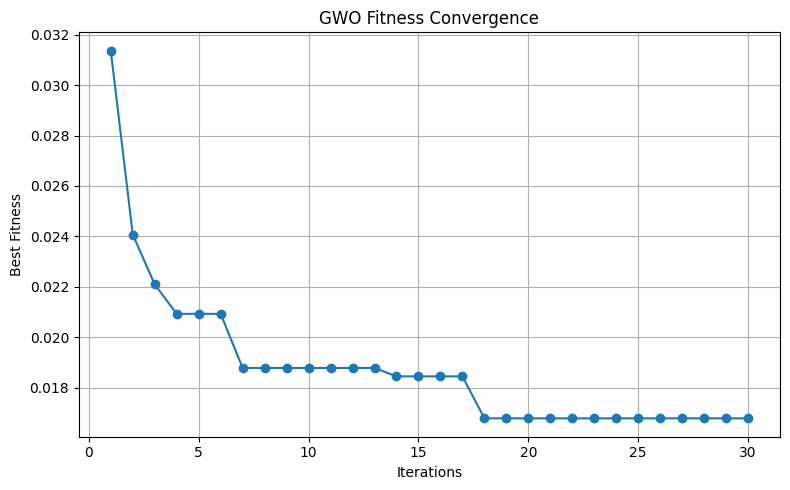

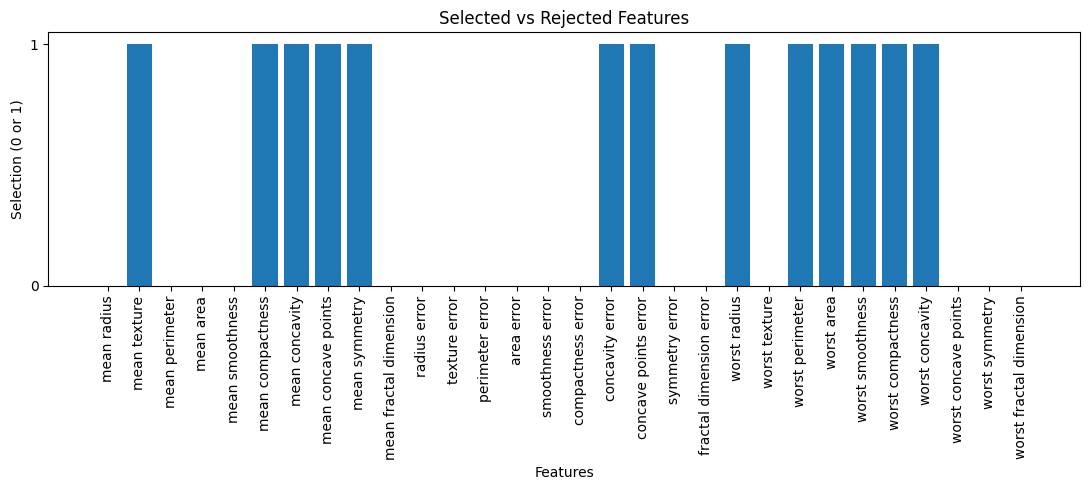

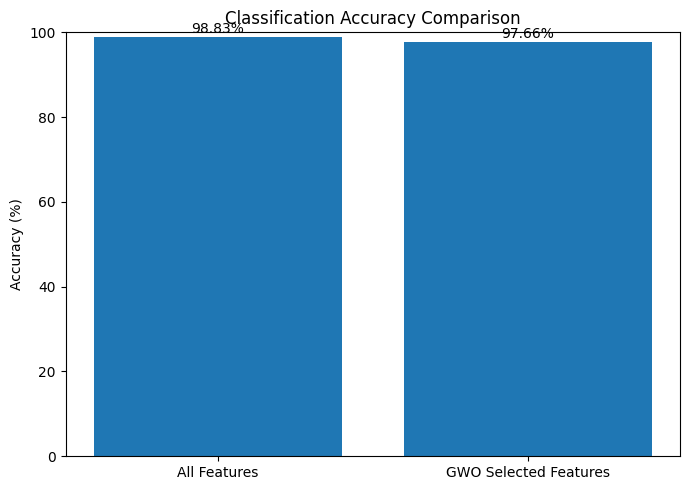

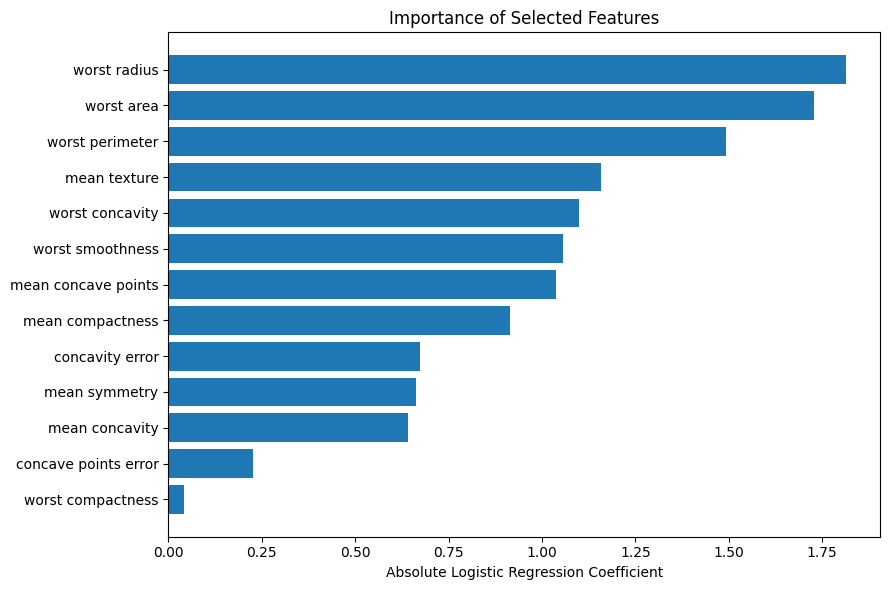

In [2]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# ==========================================
# STEP 1: LOAD DATASET
# ==========================================

data = load_breast_cancer()

X = data.data
y = data.target
feature_names = data.feature_names

N = X.shape[1]

print("Total Features:", N)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# ==========================================
# STEP 2: GWO PARAMETERS
# ==========================================

wolves_count = 10
max_iterations = 30

np.random.seed(42)

wolves = np.random.uniform(
    -2, 2, (wolves_count, N)
)

# Store convergence values
convergence = []

# ==========================================
# STEP 3: BINARY CONVERSION
# ==========================================

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -50, 50)))


def binary_position(position):
    probability = sigmoid(position)

    return (
        np.random.rand(N) < probability
    ).astype(int)


# ==========================================
# STEP 4: FITNESS FUNCTION
# ==========================================

def fitness(position):

    selected = np.where(position == 1)[0]

    if len(selected) == 0:
        return 1.0

    X_selected = X_train[:, selected]

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )

    scores = cross_val_score(
        model,
        X_selected,
        y_train,
        cv=3,
        scoring="accuracy"
    )

    error = 1 - scores.mean()

    feature_ratio = len(selected) / N

    return 0.99 * error + 0.01 * feature_ratio


# ==========================================
# STEP 5: GREY WOLF OPTIMIZATION
# ==========================================

best_binary = None
best_fitness = float("inf")

for t in range(max_iterations):

    binary_wolves = np.array([
        binary_position(wolf) for wolf in wolves
    ])

    scores = np.array([
        fitness(wolf) for wolf in binary_wolves
    ])

    order = np.argsort(scores)

    # Update best-so-far solution
    if scores[order[0]] < best_fitness:
        best_fitness = scores[order[0]]
        best_binary = binary_wolves[order[0]].copy()

    # Select leaders
    alpha = wolves[order[0]].copy()
    beta = wolves[order[1]].copy()
    delta = wolves[order[2]].copy()

    a = 2 - 2 * t / max_iterations

    new_wolves = np.zeros_like(wolves)

    for i in range(wolves_count):

        positions = []

        for leader in [alpha, beta, delta]:

            r1 = np.random.rand(N)
            r2 = np.random.rand(N)

            A = 2 * a * r1 - a
            C = 2 * r2

            D = abs(C * leader - wolves[i])

            X_new = leader - A * D

            positions.append(X_new)

        new_wolves[i] = np.mean(
            positions, axis=0
        )

    wolves = np.clip(new_wolves, -6, 6)

    convergence.append(best_fitness)

    print(
        f"Iteration {t+1}: "
        f"Best Fitness = {best_fitness:.5f}"
    )


# ==========================================
# STEP 6: SELECTED FEATURES
# ==========================================

selected_indices = np.where(best_binary == 1)[0]

print("\nSelected Features:")

for i in selected_indices:
    print(feature_names[i])

print("\nNumber of Selected Features:",
      len(selected_indices))


# ==========================================
# STEP 7: MODEL COMPARISON
# ==========================================

# Model with all features
full_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

full_model.fit(X_train, y_train)

full_predictions = full_model.predict(X_test)

full_accuracy = accuracy_score(
    y_test, full_predictions
)

# Model with selected features
if len(selected_indices) == 0:
    raise RuntimeError("No features selected.")

selected_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

selected_model.fit(
    X_train[:, selected_indices],
    y_train
)

selected_predictions = selected_model.predict(
    X_test[:, selected_indices]
)

selected_accuracy = accuracy_score(
    y_test, selected_predictions
)


# ==========================================
# STEP 8: FEATURE IMPORTANCE
# ==========================================

# Logistic Regression coefficients
coefficients = selected_model.named_steps[
    "logisticregression"
].coef_[0]

importance = np.abs(coefficients)

# ==========================================
# STEP 9: DISPLAY RESULTS
# ==========================================

print("\n========== FINAL RESULTS ==========")

print("Original Features:", N)

print("Selected Features:",
      len(selected_indices))

print("Full Dataset Accuracy:",
      round(full_accuracy * 100, 2), "%")

print("Selected Dataset Accuracy:",
      round(selected_accuracy * 100, 2), "%")

print("Feature Reduction:",
      round(
          (1 - len(selected_indices) / N) * 100,
          2
      ), "%")

print("Final Fitness:", round(best_fitness, 5))


# ==========================================
# STEP 10: GRAPH 1 - FITNESS CONVERGENCE
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, max_iterations + 1),
    convergence,
    marker='o'
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("GWO Fitness Convergence")

plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# STEP 11: GRAPH 2 - FEATURE SELECTION
# ==========================================

plt.figure(figsize=(11, 5))

plt.bar(
    feature_names,
    best_binary
)

plt.xlabel("Features")
plt.ylabel("Selection (0 or 1)")
plt.title("Selected vs Rejected Features")

plt.xticks(rotation=90)
plt.yticks([0, 1])

plt.tight_layout()
plt.show()


# ==========================================
# STEP 12: GRAPH 3 - ACCURACY COMPARISON
# ==========================================

plt.figure(figsize=(7, 5))

labels = [
    "All Features",
    "GWO Selected Features"
]

accuracies = [
    full_accuracy * 100,
    selected_accuracy * 100
]

plt.bar(labels, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("Classification Accuracy Comparison")

plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(
        i, value + 1,
        f"{value:.2f}%",
        ha='center'
    )

plt.tight_layout()
plt.show()


# ==========================================
# STEP 13: GRAPH 4 - FEATURE IMPORTANCE
# ==========================================

sorted_indices = np.argsort(importance)

plt.figure(figsize=(9, 6))

plt.barh(
    np.array(feature_names)[selected_indices][sorted_indices],
    importance[sorted_indices]
)

plt.xlabel("Absolute Logistic Regression Coefficient")
plt.title("Importance of Selected Features")

plt.tight_layout()
plt.show()
